<a href="https://colab.research.google.com/github/vasquezEmanuel/statoil-iceberg-classifier-challenge/blob/main/03_arquitectura_de_linea_de_base_y_sesgo_de_inc_angle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Línea base con CNN y análisis del sesgo de `inc_angle`

Se entrena una CNN pequeña sobre imágenes SAR de Statoil/C-CORE (barco vs. iceberg) y se estudia cuánto del rendimiento depende de **cómo se parte el conjunto** y de **si se usa el ángulo de incidencia** como entrada. También se mide el efecto del aumento de datos.

Se comparan cuatro configuraciones, cada una con tres semillas:

| Configuración | Partición | Ángulo como entrada | Aumento |
|---|---|---|---|
| A. ingenua | aleatoria | no | sí |
| B. agrupada | por ángulo | no | sí |
| C. con ángulo | por ángulo | sí | sí |
| D. sin aumento | por ángulo | no | no |

La pérdida es la entropía cruzada binaria (*log loss*). Se recomienda usar una GPU (*Entorno de ejecución → Cambiar tipo de entorno*), aunque funciona también en CPU.

## Obtención de los datos

Los datos pertenecen a la competición [Statoil/C-CORE Iceberg Classifier Challenge](https://www.kaggle.com/c/statoil-iceberg-classifier-challenge) y se descargan con la API de Kaggle. Hace falta:

1. Una cuenta de Kaggle y haber aceptado las reglas de la competición (pestaña *Rules* → *I Understand and Accept*). Sin este paso la descarga responde `403 Forbidden`.
2. Un archivo `kaggle.json` con credenciales *legacy*: en Kaggle, *Settings → API → Legacy API Credentials → Create Legacy API Key*.

Al ejecutar la celda se pide subir `kaggle.json`. El archivo se lee, se borra del disco de la sesión y nunca se guarda en el notebook. Solo se descarga `train.json` (1 604 imágenes), el único conjunto con etiquetas.

In [2]:
import os, sys, json, glob, shutil, zipfile, subprocess, importlib.util

COMPETICION = "statoil-iceberg-classifier-challenge"
DATA_DIR = "data"
TRAIN_JSON = os.path.join(DATA_DIR, "train.json")


def _instalar_dependencias():
    faltan = [p for p in ("kaggle", "py7zr") if importlib.util.find_spec(p) is None]
    if faltan:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)


def _cargar_credenciales():
    """Define KAGGLE_USERNAME y KAGGLE_KEY a partir de un kaggle.json (credenciales legacy)."""
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return
    ruta = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(ruta):
        with open(ruta) as f:
            cred = json.load(f)
    else:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError(
                "No se encontraron credenciales: coloca kaggle.json en ~/.kaggle/ "
                "o define las variables KAGGLE_USERNAME y KAGGLE_KEY."
            )
        print("Selecciona tu archivo kaggle.json")
        subido = files.upload()
        nombre = next((n for n in subido if n.lower().endswith(".json")), None)
        if nombre is None:
            raise RuntimeError("No se subió ningún archivo .json")
        cred = json.loads(subido[nombre])
        try:
            os.remove(nombre)
        except OSError:
            pass
    if "username" not in cred or "key" not in cred:
        raise RuntimeError(
            "El archivo no contiene 'username' y 'key'. Genera una Legacy API Key en "
            "Kaggle (Settings → API → Legacy API Credentials → Create Legacy API Key)."
        )
    os.environ["KAGGLE_USERNAME"] = cred["username"]
    os.environ["KAGGLE_KEY"] = cred["key"]


def _extraer():
    """Descomprime los .zip / .7z de train que haya en data/ y deja train.json en data/train.json."""
    import py7zr
    hay_trabajo = True
    while hay_trabajo:
        hay_trabajo = False
        for ruta in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True):
            if not os.path.isfile(ruta):
                continue
            nombre, destino = os.path.basename(ruta).lower(), os.path.dirname(ruta)
            if nombre.endswith(".zip") and zipfile.is_zipfile(ruta):
                with zipfile.ZipFile(ruta) as z:
                    for miembro in z.namelist():
                        if "train" in os.path.basename(miembro).lower():
                            z.extract(miembro, destino)
                os.remove(ruta)
                hay_trabajo = True
                break
            if nombre.endswith(".7z") and nombre.startswith("train"):
                with py7zr.SevenZipFile(ruta) as z:
                    z.extractall(path=destino)
                os.remove(ruta)
                hay_trabajo = True
                break
    encontrados = glob.glob(os.path.join(DATA_DIR, "**", "train.json"), recursive=True)
    if encontrados and os.path.abspath(encontrados[0]) != os.path.abspath(TRAIN_JSON):
        carpeta = os.path.relpath(encontrados[0], DATA_DIR).split(os.sep)[0]
        shutil.move(encontrados[0], TRAIN_JSON)
        shutil.rmtree(os.path.join(DATA_DIR, carpeta), ignore_errors=True)


def _descargar():
    os.makedirs(DATA_DIR, exist_ok=True)
    salida = ""
    for extra in (["-f", "train.json.7z"], []):  # primero solo train; si falla, el paquete completo
        cmd = [sys.executable, "-m", "kaggle", "competitions", "download",
               "-c", COMPETICION, "-p", DATA_DIR, *extra]
        r = subprocess.run(cmd, capture_output=True, text=True)
        salida = (r.stdout + "\n" + r.stderr).strip()
        _extraer()
        if os.path.exists(TRAIN_JSON):
            return
    raise RuntimeError(
        "No se pudo obtener train.json. Respuesta de Kaggle:\n\n" + salida + "\n\n"
        "Revisa lo siguiente:\n"
        "  1. Aceptaste las reglas en https://www.kaggle.com/c/" + COMPETICION + "/rules (error 403).\n"
        "  2. El kaggle.json es una Legacy API Key vigente; crear una nueva invalida la anterior (error 401).\n"
        "  3. Alternativa manual: descarga train.json.7z desde la pestaña Data de la competición, "
        "súbelo a la carpeta data/ y vuelve a ejecutar esta celda."
    )


if not os.path.exists(TRAIN_JSON):
    _instalar_dependencias()
    _extraer()  # cubre el caso de que el archivo ya esté en data/
if not os.path.exists(TRAIN_JSON):
    _cargar_credenciales()
    _descargar()

print(f"Datos listos: {TRAIN_JSON} ({os.path.getsize(TRAIN_JSON) / 1e6:.0f} MB)")

Datos listos: data/train.json (196 MB)


## Funciones

In [3]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score, roc_curve, confusion_matrix

warnings.filterwarnings("ignore")
SEMILLA = 42
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def cargar_datos(ruta=TRAIN_JSON):
    df = pd.read_json(ruta)
    df["inc_angle"] = pd.to_numeric(df["inc_angle"], errors="coerce")  # 'na' -> NaN
    return df


def construir_imagenes(df):
    """Tensor N x 75 x 75 x 3 con las bandas HH, HV y su promedio."""
    b1 = np.stack([np.asarray(v, dtype=np.float32).reshape(75, 75) for v in df["band_1"]])
    b2 = np.stack([np.asarray(v, dtype=np.float32).reshape(75, 75) for v in df["band_2"]])
    return np.stack([b1, b2, (b1 + b2) / 2], axis=-1)


def grupos_por_angulo(df):
    """Un grupo por valor de ángulo (4 decimales); cada imagen sin ángulo forma su propio grupo."""
    return np.array([f"na_{i}" if np.isnan(a) else f"{a:.4f}"
                     for i, a in zip(df.index, df["inc_angle"])])


def particion_ingenua(y, semilla):
    """Partición estratificada 80/20 que ignora los grupos de ángulo."""
    idx = np.arange(len(y))
    return train_test_split(idx, test_size=0.2, stratify=y, random_state=semilla)


def particion_agrupada(y, grupos, semilla):
    """Partición 80/20 estratificada en la que ningún ángulo aparece a la vez en train y validación."""
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla)
    return next(sgkf.split(np.zeros(len(y)), y, grupos))


def normalizar(X_tr, X_val):
    """Estandariza por canal con la media y desviación del conjunto de entrenamiento."""
    mu = X_tr.mean(axis=(0, 1, 2), keepdims=True)
    sd = X_tr.std(axis=(0, 1, 2), keepdims=True) + 1e-7
    return ((X_tr - mu) / sd).astype("float32"), ((X_val - mu) / sd).astype("float32")


def normalizar_angulo(a_tr, a_val):
    """Estandariza el ángulo con estadísticas de train; los valores ausentes pasan a 0 (la media)."""
    mu, sd = np.nanmean(a_tr), np.nanstd(a_tr)
    f = lambda a: np.nan_to_num((a - mu) / sd, nan=0.0).astype("float32").reshape(-1, 1)
    return f(a_tr), f(a_val)


def aumentar(imagen):
    """Giros horizontal/vertical aleatorios y rotación aleatoria múltiplo de 90°."""
    imagen = tf.image.random_flip_left_right(imagen)
    imagen = tf.image.random_flip_up_down(imagen)
    return tf.image.rot90(imagen, k=tf.random.uniform([], 0, 4, dtype=tf.int32))


def crear_dataset(X, y, entrenamiento, aumentar_datos=True, angulo=None):
    """Dataset de tf.data con entradas con nombre ('imagen' y, opcionalmente, 'angulo')."""
    entradas = {"imagen": X}
    if angulo is not None:
        entradas["angulo"] = angulo
    ds = tf.data.Dataset.from_tensor_slices((entradas, y.astype("float32")))
    if entrenamiento:
        ds = ds.shuffle(len(y), seed=SEMILLA)
        if aumentar_datos:
            ds = ds.map(lambda e, t: ({**e, "imagen": aumentar(e["imagen"])}, t),
                        num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)


def cnn_base(con_angulo=False):
    """CNN pequeña: 3 bloques Conv-BN-MaxPool, pooling global y cabeza densa."""
    entrada = keras.Input((75, 75, 3), name="imagen")
    x = entrada
    for filtros in (32, 64, 128):
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    entradas = [entrada]
    if con_angulo:
        ang = keras.Input((1,), name="angulo")
        x = layers.Concatenate()([x, layers.Dense(16, activation="relu")(ang)])
        entradas.append(ang)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    return keras.Model(entradas, layers.Dense(1, activation="sigmoid")(x))


def entrenar(modelo, ds_tr, ds_val, epocas=40, lr=1e-3, paciencia=8):
    modelo.compile(keras.optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=paciencia, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=4, min_lr=1e-6)]
    return modelo.fit(ds_tr, validation_data=ds_val, epochs=epocas, callbacks=cb, verbose=0)


def evaluar(modelo, ds, y_true):
    p = np.clip(modelo.predict(ds, verbose=0).ravel().astype("float64"), 1e-15, 1 - 1e-15)
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(log_loss=log_loss(y_true, p, labels=[0, 1]),
                accuracy=accuracy_score(y_true, pred),
                auc=roc_auc_score(y_true, p),
                recall_iceberg=tp / (tp + fn),
                especificidad=tn / (tn + fp),
                probs=p)

## Datos

In [4]:
df = cargar_datos()
X = construir_imagenes(df)
y = df["is_iceberg"].values.astype("int64")
ang = df["inc_angle"].values
grupos = grupos_por_angulo(df)
print(f"{len(df)} imágenes | iceberg: {y.mean():.1%} | sin ángulo: {np.isnan(ang).sum()} | GPUs: {len(tf.config.list_physical_devices('GPU'))}")

1604 imágenes | iceberg: 46.9% | sin ángulo: 133 | GPUs: 1


## Arquitectura

Tres bloques *Conv 3×3 → BatchNorm → MaxPool* (32, 64 y 128 filtros), *global average pooling* y una cabeza densa con *dropout*. El *pooling* global mantiene bajo el número de parámetros, importante con ~1 300 imágenes de entrenamiento. En la configuración C se añade una segunda entrada con el ángulo normalizado que se concatena antes de la cabeza densa.

In [5]:
cnn_base().summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 75, 75, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 75, 75, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 37, 37, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 18, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 18, 18, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

## Estudio: partición, ángulo y aumento de datos

Cada ejecución entrena desde cero con parada temprana (paciencia de 8 épocas sobre la pérdida de validación) y reducción de la tasa de aprendizaje. La semilla cambia tanto la inicialización como la partición, de modo que la variación entre semillas recoge ambas fuentes de incertidumbre. Se registra además qué fracción de la validación comparte ángulo con el entrenamiento.

In [6]:
SEMILLAS = [42, 7, 123]
EPOCAS = 40
resultados, historias, probas, y_validacion = [], {}, {}, {}

def ejecutar(config, semilla):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    if config == "A. ingenua":
        idx_tr, idx_val = particion_ingenua(y, semilla)
    else:
        idx_tr, idx_val = particion_agrupada(y, grupos, semilla)
    X_tr, X_val = normalizar(X[idx_tr], X[idx_val])
    con_angulo = config == "C. con ángulo"
    a_tr, a_val = normalizar_angulo(ang[idx_tr], ang[idx_val]) if con_angulo else (None, None)
    con_aumento = config != "D. sin aumento"

    ds_tr = crear_dataset(X_tr, y[idx_tr], True, con_aumento, a_tr)
    ds_val = crear_dataset(X_val, y[idx_val], False, False, a_val)
    modelo = cnn_base(con_angulo)
    t0 = time.time()
    h = entrenar(modelo, ds_tr, ds_val, EPOCAS)
    met = evaluar(modelo, ds_val, y[idx_val])

    comparte = np.isin(grupos[idx_val], list(set(grupos[idx_tr]))) & ~np.char.startswith(grupos[idx_val], "na_")
    clave = (config, semilla)
    historias[clave], probas[clave], y_validacion[clave] = h.history, met.pop("probs"), y[idx_val]
    resultados.append(dict(config=config, semilla=semilla, epocas=len(h.history["loss"]),
                           segundos=time.time() - t0, val_con_angulo_en_train=comparte.mean(), **met))
    r = resultados[-1]
    print(f"{config:15s} semilla={semilla:3d} | épocas={r['epocas']:2d} | log loss={r['log_loss']:.4f} | "
          f"acc={r['accuracy']:.3f} | AUC={r['auc']:.3f} | {r['segundos']:.0f} s")

for config in ["A. ingenua", "B. agrupada", "C. con ángulo", "D. sin aumento"]:
    for s in SEMILLAS:
        ejecutar(config, s)

A. ingenua      semilla= 42 | épocas=40 | log loss=0.2322 | acc=0.916 | AUC=0.971 | 79 s
A. ingenua      semilla=  7 | épocas=40 | log loss=0.2758 | acc=0.866 | AUC=0.953 | 56 s
A. ingenua      semilla=123 | épocas=40 | log loss=0.2496 | acc=0.888 | AUC=0.962 | 59 s
B. agrupada     semilla= 42 | épocas=40 | log loss=0.2640 | acc=0.882 | AUC=0.959 | 59 s
B. agrupada     semilla=  7 | épocas=38 | log loss=0.3095 | acc=0.875 | AUC=0.945 | 48 s
B. agrupada     semilla=123 | épocas=40 | log loss=0.2697 | acc=0.891 | AUC=0.956 | 63 s
C. con ángulo   semilla= 42 | épocas=25 | log loss=0.2698 | acc=0.892 | AUC=0.967 | 39 s
C. con ángulo   semilla=  7 | épocas=40 | log loss=0.2638 | acc=0.891 | AUC=0.958 | 57 s
C. con ángulo   semilla=123 | épocas=12 | log loss=0.6146 | acc=0.669 | AUC=0.702 | 23 s
D. sin aumento  semilla= 42 | épocas= 9 | log loss=0.6433 | acc=0.647 | AUC=0.703 | 26 s
D. sin aumento  semilla=  7 | épocas=40 | log loss=0.2433 | acc=0.900 | AUC=0.963 | 44 s
D. sin aumento  semil

### Resultados

In [7]:
res = pd.DataFrame(resultados)
metricas = ["log_loss", "accuracy", "auc", "recall_iceberg", "especificidad"]
resumen = res.groupby("config")[metricas].agg(["mean", "std"]).round(3)
resumen.columns = [f"{m} ({e})" for m, e in resumen.columns]
display(resumen)
print("Fracción de la validación cuyo ángulo también está en train:")
display(res.groupby("config")["val_con_angulo_en_train"].mean().round(3).to_frame("fracción"))
print(f"Tiempo total del estudio: {res['segundos'].sum() / 60:.1f} min")

,log_loss (mean),log_loss (std),accuracy (mean),accuracy (std),auc (mean),auc (std),recall_iceberg (mean),recall_iceberg (std),especificidad (mean),especificidad (std)
config,,,,,,,,,,
A. ingenua,0.253,0.022,0.890,0.025,0.962,0.009,0.894,0.029,0.886,0.032
B. agrupada,0.281,0.025,0.883,0.008,0.953,0.008,0.910,0.043,0.862,0.027
C. con ángulo,0.383,0.201,0.817,0.129,0.876,0.150,0.888,0.046,0.742,0.234
D. sin aumento,0.387,0.223,0.809,0.141,0.874,0.148,0.759,0.225,0.842,0.084


Fracción de la validación cuyo ángulo también está en train:


,fracción
config,
A. ingenua,0.469
B. agrupada,0.000
C. con ángulo,0.000
D. sin aumento,0.000


Tiempo total del estudio: 9.8 min


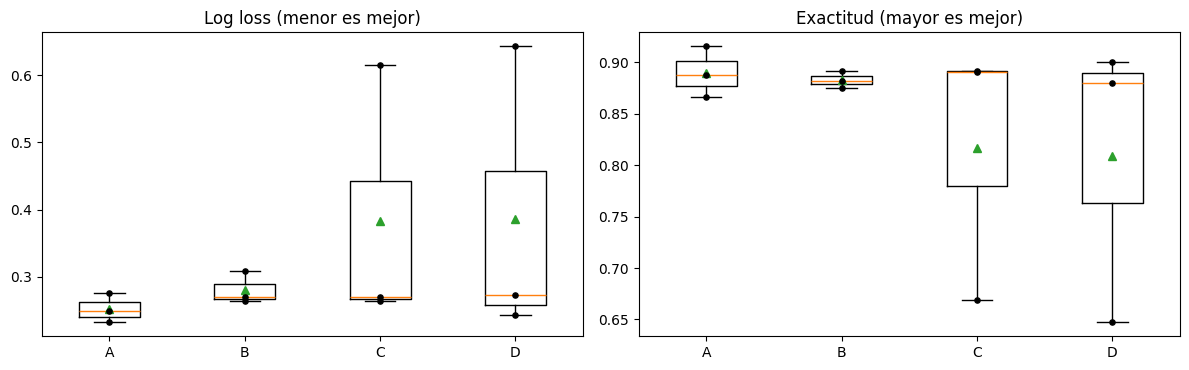

In [8]:
orden = ["A. ingenua", "B. agrupada", "C. con ángulo", "D. sin aumento"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m, titulo in zip(ejes, ["log_loss", "accuracy"], ["Log loss (menor es mejor)", "Exactitud (mayor es mejor)"]):
    datos = [res.loc[res["config"] == c, m].values for c in orden]
    ax.boxplot(datos, showmeans=True)
    ax.set_xticks(range(1, len(orden) + 1), [c.split(". ")[0] for c in orden])
    for k, d in enumerate(datos, 1):
        ax.scatter([k] * len(d), d, color="black", s=14, zorder=3)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

### Una ejecución en detalle (configuración B, primera semilla)

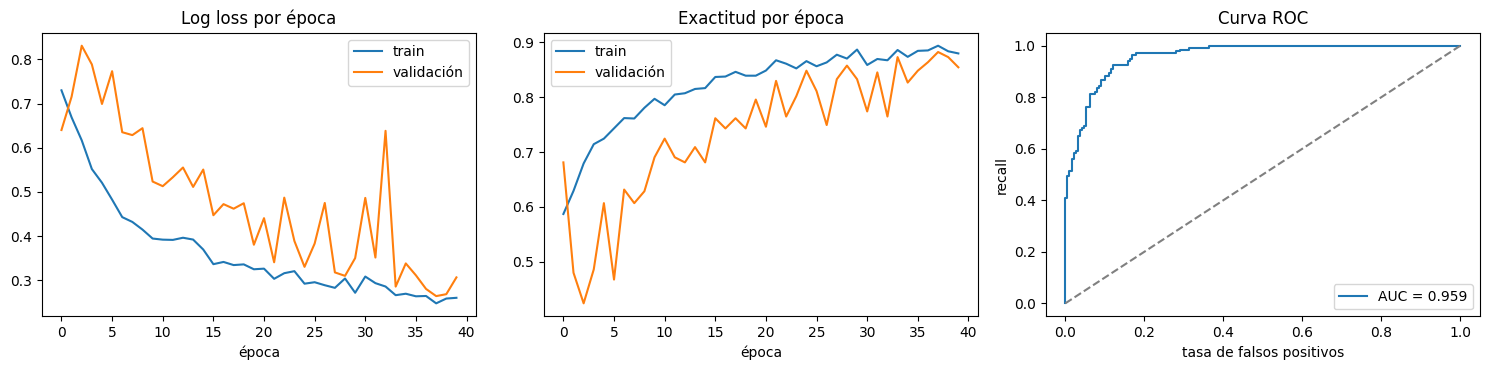

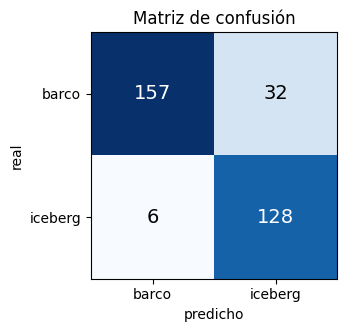

Un iceberg no detectado (clasificado como barco) es el error más costoso en navegación: recall de iceberg = 95.5%, especificidad = 83.1%


In [9]:
clave = ("B. agrupada", SEMILLAS[0])
h, p, yv = historias[clave], probas[clave], y_validacion[clave]

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
ejes[0].plot(h["loss"], label="train"); ejes[0].plot(h["val_loss"], label="validación")
ejes[0].set_title("Log loss por época"); ejes[0].set_xlabel("época"); ejes[0].legend()
ejes[1].plot(h["accuracy"], label="train"); ejes[1].plot(h["val_accuracy"], label="validación")
ejes[1].set_title("Exactitud por época"); ejes[1].set_xlabel("época"); ejes[1].legend()
fpr, tpr, _ = roc_curve(yv, p)
ejes[2].plot(fpr, tpr, label=f"AUC = {roc_auc_score(yv, p):.3f}"); ejes[2].plot([0, 1], [0, 1], "--", color="grey")
ejes[2].set_title("Curva ROC"); ejes[2].set_xlabel("tasa de falsos positivos"); ejes[2].set_ylabel("recall"); ejes[2].legend()
plt.tight_layout(); plt.show()

cm = confusion_matrix(yv, (p >= 0.5).astype(int))
fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["barco", "iceberg"]); ax.set_yticks([0, 1], ["barco", "iceberg"])
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.grid(False); ax.set_title("Matriz de confusión")
plt.show()
print(f"Un iceberg no detectado (clasificado como barco) es el error más costoso en navegación: "
      f"recall de iceberg = {cm[1, 1] / cm[1].sum():.1%}, especificidad = {cm[0, 0] / cm[0].sum():.1%}")

### Lectura de los resultados

In [10]:
m = res.groupby("config")["log_loss"].agg(["mean", "std"])
def comparar(a, b, descripcion):
    d = m.loc[a, "mean"] - m.loc[b, "mean"]
    ruido = max(m.loc[a, "std"], m.loc[b, "std"])
    if abs(d) <= ruido:
        veredicto = "la diferencia es menor que la variación entre semillas: no es concluyente"
    else:
        veredicto = f"{a[0]} es " + ("peor" if d > 0 else "mejor") + " (log loss " + ("mayor" if d > 0 else "menor") + ")"
    print(f"- {descripcion}: {a[0]} {m.loc[a, 'mean']:.3f} vs {b[0]} {m.loc[b, 'mean']:.3f} → {veredicto}.")

print("Comparaciones de log loss (media de 3 semillas; la desviación entre semillas actúa como umbral de ruido):\n")
comparar("A. ingenua", "B. agrupada", "Efecto de agrupar la partición")
comparar("C. con ángulo", "B. agrupada", "Efecto de añadir el ángulo como entrada")
comparar("D. sin aumento", "B. agrupada", "Efecto del aumento de datos")
fuga = res.loc[res["config"] == "A. ingenua", "val_con_angulo_en_train"].mean()
print(f"\nCon la partición ingenua, {fuga:.0%} de la validación comparte ángulo con el entrenamiento; "
      f"con la agrupada, 0%.")

Comparaciones de log loss (media de 3 semillas; la desviación entre semillas actúa como umbral de ruido):

- Efecto de agrupar la partición: A 0.253 vs B 0.281 → A es mejor (log loss menor).
- Efecto de añadir el ángulo como entrada: C 0.383 vs B 0.281 → la diferencia es menor que la variación entre semillas: no es concluyente.
- Efecto del aumento de datos: D 0.387 vs B 0.281 → la diferencia es menor que la variación entre semillas: no es concluyente.

Con la partición ingenua, 47% de la validación comparte ángulo con el entrenamiento; con la agrupada, 0%.


**Cómo interpretar estas cifras**

- Con solo 3 semillas y ~320 imágenes de validación, las diferencias pequeñas no son concluyentes; por eso el texto anterior las contrasta con la dispersión observada.
- La validación se usa también para la parada temprana, de modo que sus métricas son algo optimistas frente a un conjunto de prueba independiente.
- Una configuración con ángulo que no mejore a la que no lo usa es una buena noticia: la señal viene de la imagen y no de la geometría de la toma.
- La partición agrupada es la referencia más honesta; una mejora que solo aparece en la partición ingenua debe tomarse con cautela.